#### Loading packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

#### Directories

In [2]:
Path.cwd()

WindowsPath('c:/Users/PC_DS_ECON_5/Desktop/data-analytics-python-example/notebooks')

In [3]:
ROOT_DIR = Path('c:/Users/PC_DS_ECON_5/Desktop/data-analytics-python-example')
DATA_DIR = ROOT_DIR / 'data'

#### Importing the data

In [4]:
df = pd.read_parquet(DATA_DIR / 'nlsy97_jobs.parquet')

Objective:
distribution of hourly pay (in particular: logarithm of hourly pay)
by ethnicity


Unit of observation:
using the `value_counts()` twice to figure it out

In [5]:
# is our dataset a panel of individuals over time?
# the first value_counts() counts the number of occurrences for each unique combination
# of the variables
# the second value_counts() counts the number of occurrences of the the counts from the 
# from the first value_counts()
print(df[['person_id', 'year']].value_counts().value_counts())
# multiple person-year combinations that appear multiple times

# is it person X job_rank?
print(df[['person_id', 'job_rank']].value_counts().value_counts())

# is it person X year X job_rank?
print(df[['person_id', 'year', 'job_rank']].value_counts().value_counts())

count
1     52792
2     26247
3      8687
4      2492
5       686
6       196
7        65
8        16
9        12
11        3
10        2
15        1
13        1
12        1
Name: count, dtype: int64
count
1     4569
2     2419
3     1714
4     1327
5     1104
6     1055
7      897
19     715
20     701
8      694
18     675
9      668
17     625
10     592
16     537
11     515
13     512
12     508
14     479
15     476
Name: count, dtype: int64
count
1    146705
Name: count, dtype: int64


Unit of observation: job X person X year

Next objective:
one observation per individual

subset the dataset: 
select only the main job (`job_rank=1`, highest salience job) of each individual from the last available year

using `.loc`

last available year to be identified using `max()`

In [6]:
# select the maximum value of year (here it is the most recent)
# drop_duplicates() is optional
last_available_year = df['year'].drop_duplicates().max()
last_available_year

np.int64(2023)

In [7]:
# df1 is just a subset of the original dataframe
# main jobs for every individual for the last available year
# restriction of the sample: only individuals with a job are included 
df1 = (
    df.loc[
        df['year'].eq(last_available_year) & 
        df['job_rank'].eq(1),:]
    .reset_index(drop=True)
    .copy()
)

Checking that there is only one observation per individual in `df1`.

In [8]:
# checking whether every identifier appears only once
df1['person_id'].is_unique

True

Creating the variable `log_hpay`: natural logarithm of hourly pay `hpay`.

For log transformation there is a dedicated function in numpy: 
`numpy.log()`.

There is one point to be taken into account: 
how to handle values of zero or negative values --> let `log_hpay` be missing in these cases (log is not defined)

Define `log_hpay` only if the value of `hpay` is not missing and is greater than zero: use the function `notna()` for identifying non-missing values and the function `gt()` (greater than) for identifying (strictly) positive values

Distinguish between two cases: depending on whether the log hourly pay can be defined or not: let us use the `numpy.where()` function for this purpose.




In [9]:
df1['log_hpay'] = np.where(
    # column of Trues and Falses
    # not missing hpay and positive hpay
    df1['hpay'].notna() & df1['hpay'].gt(0),
    # if condition holds
    np.log(df1['hpay']),
    # if condition does not hold: missing value
    pd.NA # pandas missing value
)

Checking the datatype of the new variable

To understand how `pandas`, `numpy`, and `matplotlib` handles it

Our objective: unambiguously numerical datatype (Int/integer, Float/floating point or something along that line) 

In [10]:
print(df1.log_hpay.dtype)
df1.dtypes

object


person_id              Int64
year                   Int64
hrs_per_week           Int64
tenure_in_weeks        Int64
hpay                 Float64
educ_cat            category
experience_proxy     Float64
testscore97_pct      Float64
occupation_group    category
industry_group      category
gender                string
ethnicity             string
age                  Float64
job_rank               Int64
log_hpay              object
dtype: object

Easiest way to make sure that more-or-less all variables have some pandas data type (numbers are numbers, text is text, categories are categories etc)

Call the function `convert_dtypes()`

Usually this is enough

If not: a closer look is required (then something did not work as intended)

In [11]:
df1 = df1.convert_dtypes()
df1.dtypes

person_id              Int64
year                   Int64
hrs_per_week           Int64
tenure_in_weeks        Int64
hpay                 Float64
educ_cat            category
experience_proxy     Float64
testscore97_pct      Float64
occupation_group    category
industry_group      category
gender                string
ethnicity             string
age                  Float64
job_rank               Int64
log_hpay             Float64
dtype: object

#### Create histograms of log hourly pay by ethnicity
A first way to visually represent a distribution is a histogram.
Both for continuous and discrete variables.
Parenthesis:
Among numerical variables (approximate definitions):
 - continuous variables: they can take any value in an interval
 - discrete variables: they can take a finite or a countably infinite number of values

Hourly pay (without further information) is a continuous variable
 -> In principle it can take any positive value
Therefore: Log hourly pay is also a continuous variable
 -> In principle any real number

Histograms are good for displaying distributions of both types of variables 

Most conventional way to create a histogram for a continuous variable:
 - group values into equal-sized intervals (creating bins / binning observations)
 - calculate the (relative) frequency of observations belonging to each interval / bin
 - plot the (relative) frequencies against the bins




Defining the bins

In [12]:
# minimum and maximum values of our variable
print(df1['log_hpay'].min(), df1['log_hpay'].max())
# approximate binsize / interval length for twenty equal-sized bins 
(df1['log_hpay'].max() - df1['log_hpay'].min()) / 20

-3.506557897319982 5.521380914662076


np.float64(0.45139694059910285)

Need to define the interval bounds: range of values

Let us use here: `numpy.arange()`

In [13]:
binwidth=0.5 # length of the equal-sized intervals 
bins = np.arange(
    # start of the range of interval bounds: 
    # a little bit below the minimum (this is arbitrary)
    start=df1['log_hpay'].min() - binwidth,
    # where the range should stop / upper bound
    # a little bit above the maximum value
    stop=df1['log_hpay'].max() + 2*binwidth,
    # interval length/ binwidth
    step=binwidth 
)
bins 
# there are some extra intervals, 
# but having a little more is not a problem
# having less can be a problem

array([-4.0065579, -3.5065579, -3.0065579, -2.5065579, -2.0065579,
       -1.5065579, -1.0065579, -0.5065579, -0.0065579,  0.4934421,
        0.9934421,  1.4934421,  1.9934421,  2.4934421,  2.9934421,
        3.4934421,  3.9934421,  4.4934421,  4.9934421,  5.4934421,
        5.9934421,  6.4934421])

Assign the observations to the bins according to the value of 
`log_hpay`.

Out of a continuous variable we are creating a discrete variable / categorical variable such that every category is an interval/bin.

For this purpose there is the function: `pandas.cut()`

In [14]:
df1['log_hpay_bin'] = pd.cut(
    x=df1['log_hpay'],
    bins=bins
)

We obtain a variable with categorical data type: 

In [15]:
df1['log_hpay_bin'].dtype

CategoricalDtype(categories=[  (-4.007, -3.507],   (-3.507, -3.007],   (-3.007, -2.507],
                    (-2.507, -2.007],   (-2.007, -1.507],   (-1.507, -1.007],
                    (-1.007, -0.507], (-0.507, -0.00656],  (-0.00656, 0.493],
                      (0.493, 0.993],     (0.993, 1.493],     (1.493, 1.993],
                      (1.993, 2.493],     (2.493, 2.993],     (2.993, 3.493],
                      (3.493, 3.993],     (3.993, 4.493],     (4.493, 4.993],
                      (4.993, 5.493],     (5.493, 5.993],     (5.993, 6.493]],
, ordered=True, categories_dtype=interval[float64, right])

The following is left-open and right-closed interval:
$(-4.007, -3.507]$
One could also use the continental notation:
$]-4.007, -3.507]$


Parenthesis:

In [16]:
interval= pd.Interval(left=-4.007, right=-3.507, closed='both')
print(interval)

[-4.007, -3.507]


Binning is done at this point.
We can proceed with the computation of the relative frequencies by ethnicity.

In [17]:
# unconditional relative frequencies by log hourly pay bin
# general idea of the distribution (unconditionally / not by ethnicity)
df1['log_hpay_bin'].value_counts().sort_index()

log_hpay_bin
(-4.007, -3.507]         1
(-3.507, -3.007]         0
(-3.007, -2.507]         0
(-2.507, -2.007]         0
(-2.007, -1.507]         1
(-1.507, -1.007]         2
(-1.007, -0.507]         2
(-0.507, -0.00656]       1
(-0.00656, 0.493]        5
(0.493, 0.993]          12
(0.993, 1.493]           6
(1.493, 1.993]          26
(1.993, 2.493]         156
(2.493, 2.993]         889
(2.993, 3.493]        1448
(3.493, 3.993]         960
(3.993, 4.493]         469
(4.493, 4.993]         110
(4.993, 5.493]           0
(5.493, 5.993]          71
(5.993, 6.493]           0
Name: count, dtype: int64

In [18]:
df1['ethnicity'].value_counts()
# four categories
# US categories

ethnicity
Non-Black / Non-Hispanic     2845
Black                         682
Hispanic                      579
Mixed Race (Non-Hispanic)      53
Name: count, dtype: int64[pyarrow]

Let us compute relative frequencies for each bin by ethnicity. Let us use `pandas.crosstab()`, let the rows of the cross-tabulation be the bins/intervals of log hourly pay and let the columns of the cross-tabulation be the ethnicity categories.

Each cell is the share/proportion of observations within the given ethnicity (column) having a log hourly pay belonging to the given interval (index/row) 

In [19]:
ct = pd.crosstab(
    index=df1['log_hpay_bin'],
    columns=df1['ethnicity'],
    # relative within ethnicities, within each column
    normalize='columns'
).reset_index() # log hourly pay intervals/bins as a separate column instead of index
# remove the superfluous columns label
ct.columns.name=None


Intervals are not particularly appropriate for plotting in `matplotlib`. Using them directly is not an option.

Therefore: instead of plotting the intervals, let us plot the interval midpoints: halfway between lower bound and upper bound.

To get the midpoint, let us the `mid` attribute of intervals. Let us define a function `get_midpoint()` that does this. Let us use `transform()` to apply this function to every (interval) value in the column `log_hpay_bin`.


In [20]:
# midpoint of an interval: average value of the bounds
print(interval.mid, (interval.right + interval.left)/2)
# function that extracts the midpoint of an interval
def get_midpoint(interval):
    return interval.mid
# use this function within transform(), 
# applying it to every value of our variable/column
ct['log_hpay_bin_mid'] = ct['log_hpay_bin'].transform(get_midpoint)

-3.7569999999999997 -3.7569999999999997


In [21]:
ct[['log_hpay_bin', 'log_hpay_bin_mid']]

,log_hpay_bin,log_hpay_bin_mid
0,"(-4.007, -3.507]",-3.75700
1,"(-2.007, -1.507]",-1.75700
2,"(-1.507, -1.007]",-1.25700
3,"(-1.007, -0.507]",-0.75700
4,"(-0.507, -0.00656]",-0.25678
5,"(-0.00656, 0.493]",0.24322
6,"(0.493, 0.993]",0.74300
7,"(0.993, 1.493]",1.24300
8,"(1.493, 1.993]",1.74300
9,"(1.993, 2.493]",2.24300


Plotting:
plot relative frequencies by ethnicity (three ethnicity columns)
against
the midpoints
histogram: let us create bar plots

three plots one after the other / below each other

three axes objects

In [22]:
ct # abbreviation for cross-tabulation (arbitrary name)

,log_hpay_bin,Black,Hispanic,Mixed Race (Non-Hispanic),Non-Black / Non-Hispanic,log_hpay_bin_mid
0,"(-4.007, -3.507]",0.000000,0.001727,0.000000,0.000000,-3.75700
1,"(-2.007, -1.507]",0.001466,0.000000,0.000000,0.000000,-1.75700
2,"(-1.507, -1.007]",0.000000,0.001727,0.000000,0.000351,-1.25700
3,"(-1.007, -0.507]",0.000000,0.000000,0.000000,0.000703,-0.75700
4,"(-0.507, -0.00656]",0.000000,0.000000,0.000000,0.000351,-0.25678
5,"(-0.00656, 0.493]",0.001466,0.003454,0.000000,0.000703,0.24322
6,"(0.493, 0.993]",0.001466,0.003454,0.000000,0.003163,0.74300
7,"(0.993, 1.493]",0.000000,0.003454,0.000000,0.001406,1.24300
8,"(1.493, 1.993]",0.005865,0.005181,0.000000,0.006678,1.74300
9,"(1.993, 2.493]",0.058651,0.031088,0.037736,0.033743,2.24300


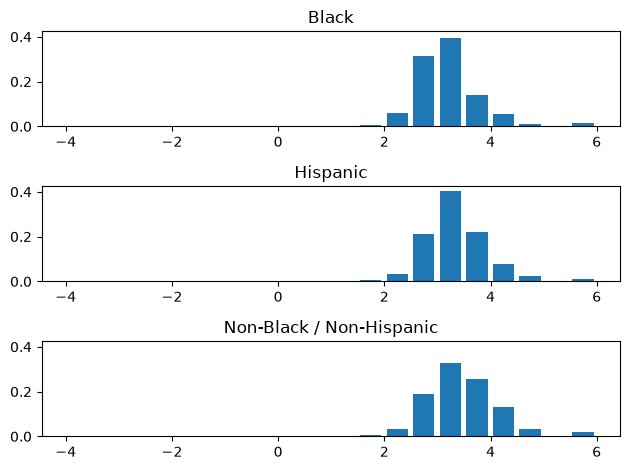

In [23]:
# matplotlib.pyplot - plt
# three plots below each other
fig, axs = plt.subplots(nrows=3, ncols=1, sharey=True)
# uppermost plot axs[0] because indexing in Python starts with 0
# plot at the top is indexed zero
# second plot from the top is indexed 1
# third plot from the top is indexed 2
axs[0].bar(
    # location of the bars / the horizontal placement of the bars
    # each time: the midpoint of the corresponding log hourly pay interval
    x=ct['log_hpay_bin_mid'],
    # height: relative frequencies (shares/proportions) associated with the given interval
    height=ct['Black'],
    # width is defined in units of the horizontal axis
    # 80% of the corresponding interval width
    width=0.8 * binwidth
)
axs[0].set_title('Black')
axs[1].bar(
    x=ct['log_hpay_bin_mid'],
    height=ct['Hispanic'],
    width=0.8 * binwidth
)
axs[1].set_title('Hispanic')
axs[2].bar(
    x=ct['log_hpay_bin_mid'],
    height=ct['Non-Black / Non-Hispanic'],
    width=0.8 * binwidth
)
axs[2].set_title('Non-Black / Non-Hispanic')

# call at the very end (without this I had some congestion)
fig.tight_layout()


Let us produce the same plot with less code using a `for` loop

In [24]:
# iterate over the three ethnicities
for ethnicity in ['Black', 'Hispanic', 'Non-Black / Non-Hispanic']:
    print(ethnicity)

Black
Hispanic
Non-Black / Non-Hispanic


In [25]:
# iterate over the three ethnicities plus the index of each of them in the list
# iterate over both index and content
for i, ethnicity in enumerate(['Black', 'Hispanic', 'Non-Black / Non-Hispanic']):
    print('index:', i)
    print('content:', ethnicity)
# we need the indices as well: axs[0], axs[1], axs[2]

index: 0
content: Black
index: 1
content: Hispanic
index: 2
content: Non-Black / Non-Hispanic


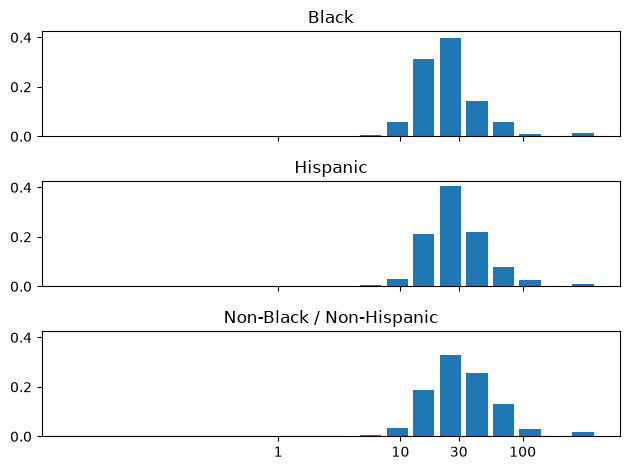

In [26]:
fig, axs = plt.subplots(nrows=3, 
                        ncols=1, 
                        sharey=True, # same scale for the vertical axis 
                        sharex=True # same scale for the horizontal axis
                        )
# what changes from one plot to the other
# in this case: the only thing that changes: ethnicity, index of the subplot axs[0], axs[1], axs[2]
for i, ethnicity in enumerate(['Black', 'Hispanic', 'Non-Black / Non-Hispanic']):
    axs[i].bar(
        x=ct['log_hpay_bin_mid'],
        height=ct[ethnicity],
        width=0.8 * binwidth
    )
    axs[i].set_title(ethnicity)

# label the ticks on the horizontal axis
# for specific values of hourly pay (instead of log hourly pay)
ticks_labels = [1,10,30,100]
# the locations should be in logs (because this is how our variable is constructed)
ticks_locations = np.log(ticks_labels)
axs[2].set_xticks(ticks=ticks_locations, labels=ticks_labels)
# call at the very end (without this I had some congestion)
fig.tight_layout()

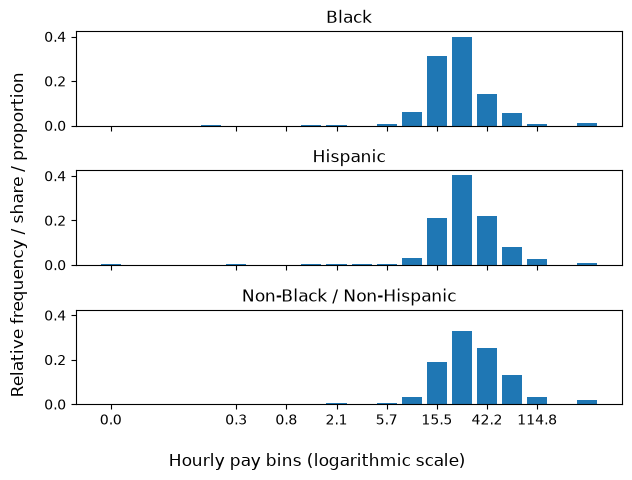

In [27]:
fig, axs = plt.subplots(nrows=3, 
                        ncols=1, 
                        sharey=True, # same scale for the vertical axis 
                        sharex=True # same scale for the horizontal axis
                        )
# what changes from one plot to the other
# in this case: the only thing that changes: ethnicity, index of the subplot axs[0], axs[1], axs[2]
# i= 0 (Black), 1 (Hispanic), 2 (Non-Black / Non-Hispanic)
# index of the value in the list
for i, ethnicity in enumerate(['Black', 'Hispanic', 'Non-Black / Non-Hispanic']):    
    axs[i].bar(
        x=ct['log_hpay_bin_mid'],
        height=ct[ethnicity],
        width=0.8 * binwidth
    )
    axs[i].set_title(ethnicity)
# locations of the bars
# collecting the values of the x axis, making sure that they are numbers (not categories), 
# converting to a list
ticks_locations = ct['log_hpay_bin_mid'].astype(float).to_list()
# keeping only every second tick (to avoid overlapping labels)
ticks_locations = ticks_locations[::2]

# for the labels: let us have the values in hourly pay (not log hourly pay)
# inverse of the log: exponential
# round the values to 1 decimal place
ticks_labels = np.round(np.exp(ticks_locations), decimals=1)

axs[2].set_xticks(ticks=ticks_locations, labels=ticks_labels)
# common vertical axis
fig.supylabel('Relative frequency / share / proportion')
# common horizontal axis
fig.supxlabel('Hourly pay bins (logarithmic scale)')


# call at the very end (without this I had some congestion)
fig.tight_layout()

Alternative way: 
one plot, for each interval: the three bars (corresponding to the three groups) are next to each other / side-by-side

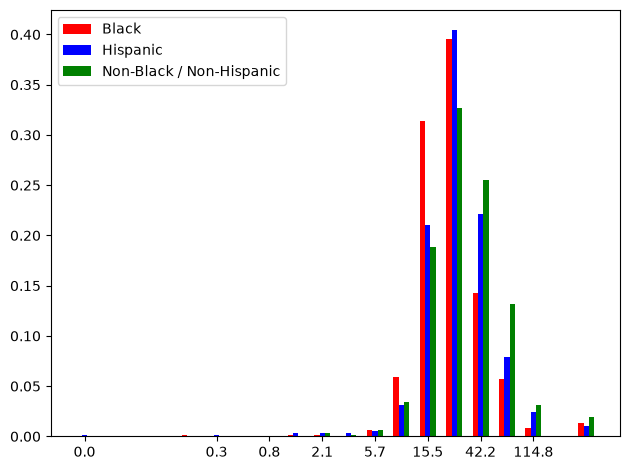

In [28]:
fig, ax = plt.subplots()
# thinner bars: multiple bars can be plotted within the same interval
# change location of the bars slightly: for every interval, plot three bars next to each other 
# using a for loop: what changes from one data series to the other:
# - ethnicity, location of the bars, eventually the color (if set by hand)
ethnicities = ['Black', 'Hispanic', 'Non-Black / Non-Hispanic']
colors = ['red','blue','green']
# shift the bars a little to the left for Blacks and a little to the right for Non-Blacks / Non-Hispanics
bar_shift = [(-0.2) * binwidth, 0, (0.2) * binwidth]
# iterate over i in 0 to 2 [0,1,2]
for i in range(3):
    ax.bar(
        # have explicitly numerical type for the data plotted on the horizontal axis
        # choose the alignment according to the corresponding index
        x=ct['log_hpay_bin_mid'].astype(float) + bar_shift[i],
        height=ct[ethnicities[i]], # choose ethnicity according to the corresponding index
        width=0.2 * binwidth,
        label=ethnicities[i], # choose ethnicity according to the corresponding index
        color=colors[i] # choose color according to the corresponding index
    )
ticks_locations = ct['log_hpay_bin_mid'].astype(float)[::2] # every second value
ticks_labels = np.round(np.exp(ticks_locations), decimals=1) # labels in hourly pay (not in logs)
ax.set_xticks(ticks=ticks_locations, labels=ticks_labels)
ax.legend()
fig.tight_layout()

Cumulative distribution plots

Works for any variable for which an ordering can be defined

Even for ordered categorical variables

We would like to plot the real-world equivalent of cumulative probabilities:

For each $value$, the cumulative probability of log hourly pay is $ \mathbb{P}[log\_hpay \leq value]$ (latex math)

What is the probability that the value of the variable log hourly pay is lower than or equal to a specific value.

In the reality, we can plot cumulative shares / cumulative proprotions / cumulative relative frequncies corresponding to different values:

For each value on the horizontal x-axis, we plot on the y axis the share of observations such that our variable takes on a value that is lower or equal to the value on the x-axis. Cumulative share of observations with a value less than or equal to the particular value. 

For each $x$, we plot $y= \mathbb{P}[log\_hpay \leq x]$




In our case: cumulative relative frequencies by ethnicity

$\text{cumulative probability associated with the value } x \text{ within each/the given ethnicity} = \mathbb{P}[log\_hpay \leq x | ethnicity]$

cumulative relative frequencies:
 - cumulative sum (`cumsum()`) of relative frequencies within each ethnicity (`value_counts()`)
 - if the values are sorted in ascending order (for the cumulative sum, values need to be sorted by log hourly pay within each ethnicity) (`sort_values()`)

reminder: we have observations about the main job of individuals in the sample from a specific year (last available year 2023)

Computing relative frequencies of log hourly pay within ethnicity

In [33]:
# df1 selected dataframe (one observation per individual from year 2023 on the main job)
# value_counts(), within ethnicity: groupby()
df2 = (
    df1
        # grouping observations by ethnicity and selecting log_hpay (variable of interest)
        .groupby('ethnicity')['log_hpay']  
        .value_counts(normalize=True) # normalize=True (relative frequencies)
        .reset_index()
        .copy()
)

Sorting the rows of `df2` by log hourly pay within ethnicity in ascending order (important for the cumulative sum)


In [36]:
df2 = (
    df2
        # first the grouping variable, 
        # then within the grouping variable the variable of interest (var used for sorting) 
        .sort_values(['ethnicity', 'log_hpay'], ignore_index=True)
        .copy()
)

Proportions (relative frequencies) ---> Cumulative proportions (cumulative relative frequencies)

Use `cumsum()` 

By ethnicity: Before `cumsum()`, use `groupby()` 

In [38]:
# let us create a new column in the df2 data frame called cum_proportion
df2['cum_proportion'] = (
    df2
        # grouping by ethnicity and selecting the proportion column
        .groupby('ethnicity')['proportion']
        .cumsum()
)

Plotting

Cumulative relative frequencies for groups/ethnicities are stored in the same dataframe at this point

Split the dataframe by ethnicity

Let us create a dictionary (key-value pairs): keys should be the groups, and the values the corresponding dataframes



In [ ]:
# empty dictionary
df3dict = {}
# using a for loop
# for each ethnicity in ['Black', 'Hispanic', 'Non-Black / Non-Hispanic']
for ethnicity in ['Black', 'Hispanic', 'Non-Black / Non-Hispanic']:
    # let the entry of the dictionary associated with key=ethnicity
    # be the observations from df2 dataframe 
    # such that df2['ethnicity']=ethnicity
    df3dict[ethnicity] = (
        df2
            .loc[df2['ethnicity'].eq(ethnicity),:]
            .reset_index(drop=True)
            .copy()
    )

`df3dict` contains three dataframes, each corresponding to a particular ethnicity

Plotting

Empirical cumulative frequencies look like step functions
 - most natural way to represent them


In [45]:
df3dict['Black']

,ethnicity,log_hpay,proportion,cum_proportion
0,Black,-1.89712,0.001466,0.001466
1,Black,0.364643,0.001466,0.002933
2,Black,0.756122,0.001466,0.004399
3,Black,1.832581,0.001466,0.005865
4,Black,1.909543,0.001466,0.007331
...,...,...,...,...
312,Black,4.60517,0.002933,0.982405
313,Black,4.748231,0.001466,0.983871
314,Black,4.781054,0.001466,0.985337
315,Black,4.828314,0.001466,0.986804


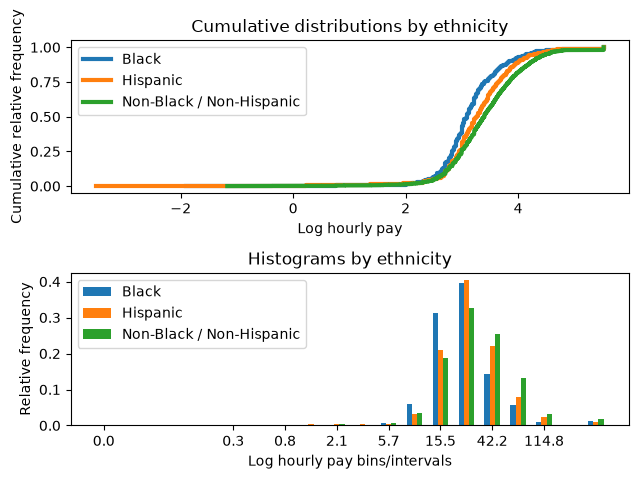

In [58]:
fig, axs = plt.subplots(nrows=2, ncols=1)
# step plot
# let us specify it as:
# for each x value, 
# let the corresponding y value apply 
# until the next available x value in the dataframe 
# (on the right of/above the current x value)


for ethnicity in ['Black', 'Hispanic', 'Non-Black / Non-Hispanic']:
    # selecting the relevant dataframe (for the given ethnicity)
    df3_current = df3dict[ethnicity]
    # step plot
    axs[0].step(
        x=df3_current['log_hpay'], # variable of interest
        y=df3_current['cum_proportion'], # corresponding cumulative proportion
        where='post', # each time the y value applies above the x value (until the next x value)
        label=ethnicity,
        linewidth=3
    )
axs[0].legend()
axs[0].set_title('Cumulative distributions by ethnicity')
axs[0].set_ylabel('Cumulative relative frequency')
axs[0].set_xlabel('Log hourly pay')

for i in range(3):
    axs[1].bar(
        # have explicitly numerical type for the data plotted on the horizontal axis
        # choose the alignment according to the corresponding index
        x=ct['log_hpay_bin_mid'].astype(float) + bar_shift[i],
        height=ct[ethnicities[i]], # choose ethnicity according to the corresponding index
        width=0.2 * binwidth,
        label=ethnicities[i], # choose ethnicity according to the corresponding index
    )
axs[1].set_title('Histograms by ethnicity')
axs[1].set_ylabel('Relative frequency')
axs[1].set_xlabel('Log hourly pay bins/intervals')
ticks_locations = ct['log_hpay_bin_mid'].astype(float)[::2] # every second value
ticks_labels = np.round(np.exp(ticks_locations), decimals=1) # labels in hourly pay (not in logs)
axs[1].set_xticks(ticks=ticks_locations, labels=ticks_labels)
axs[1].legend()





fig.tight_layout()

Quantiles

Inverse of cumulative probabilities / cumulative proportions

Examples: percentiles, median, deciles, ...

Up to now: Cumulative proportion associated with a certain value 

Quantiles: Inverting the question --> Value associated with a cumulative proportion

For each proportion $x$, what is the value $y$ such that $\mathbb{P}[log\_hpay \leq y] \approx x$ 
 - i.e. in words: 
    - such that the cumulative proportion/relative frequency associated with the value $y$ is approximately equal $x$
    - for approximately $x$ proportion of observations the log hourly pay is less than or equal to $y$ 





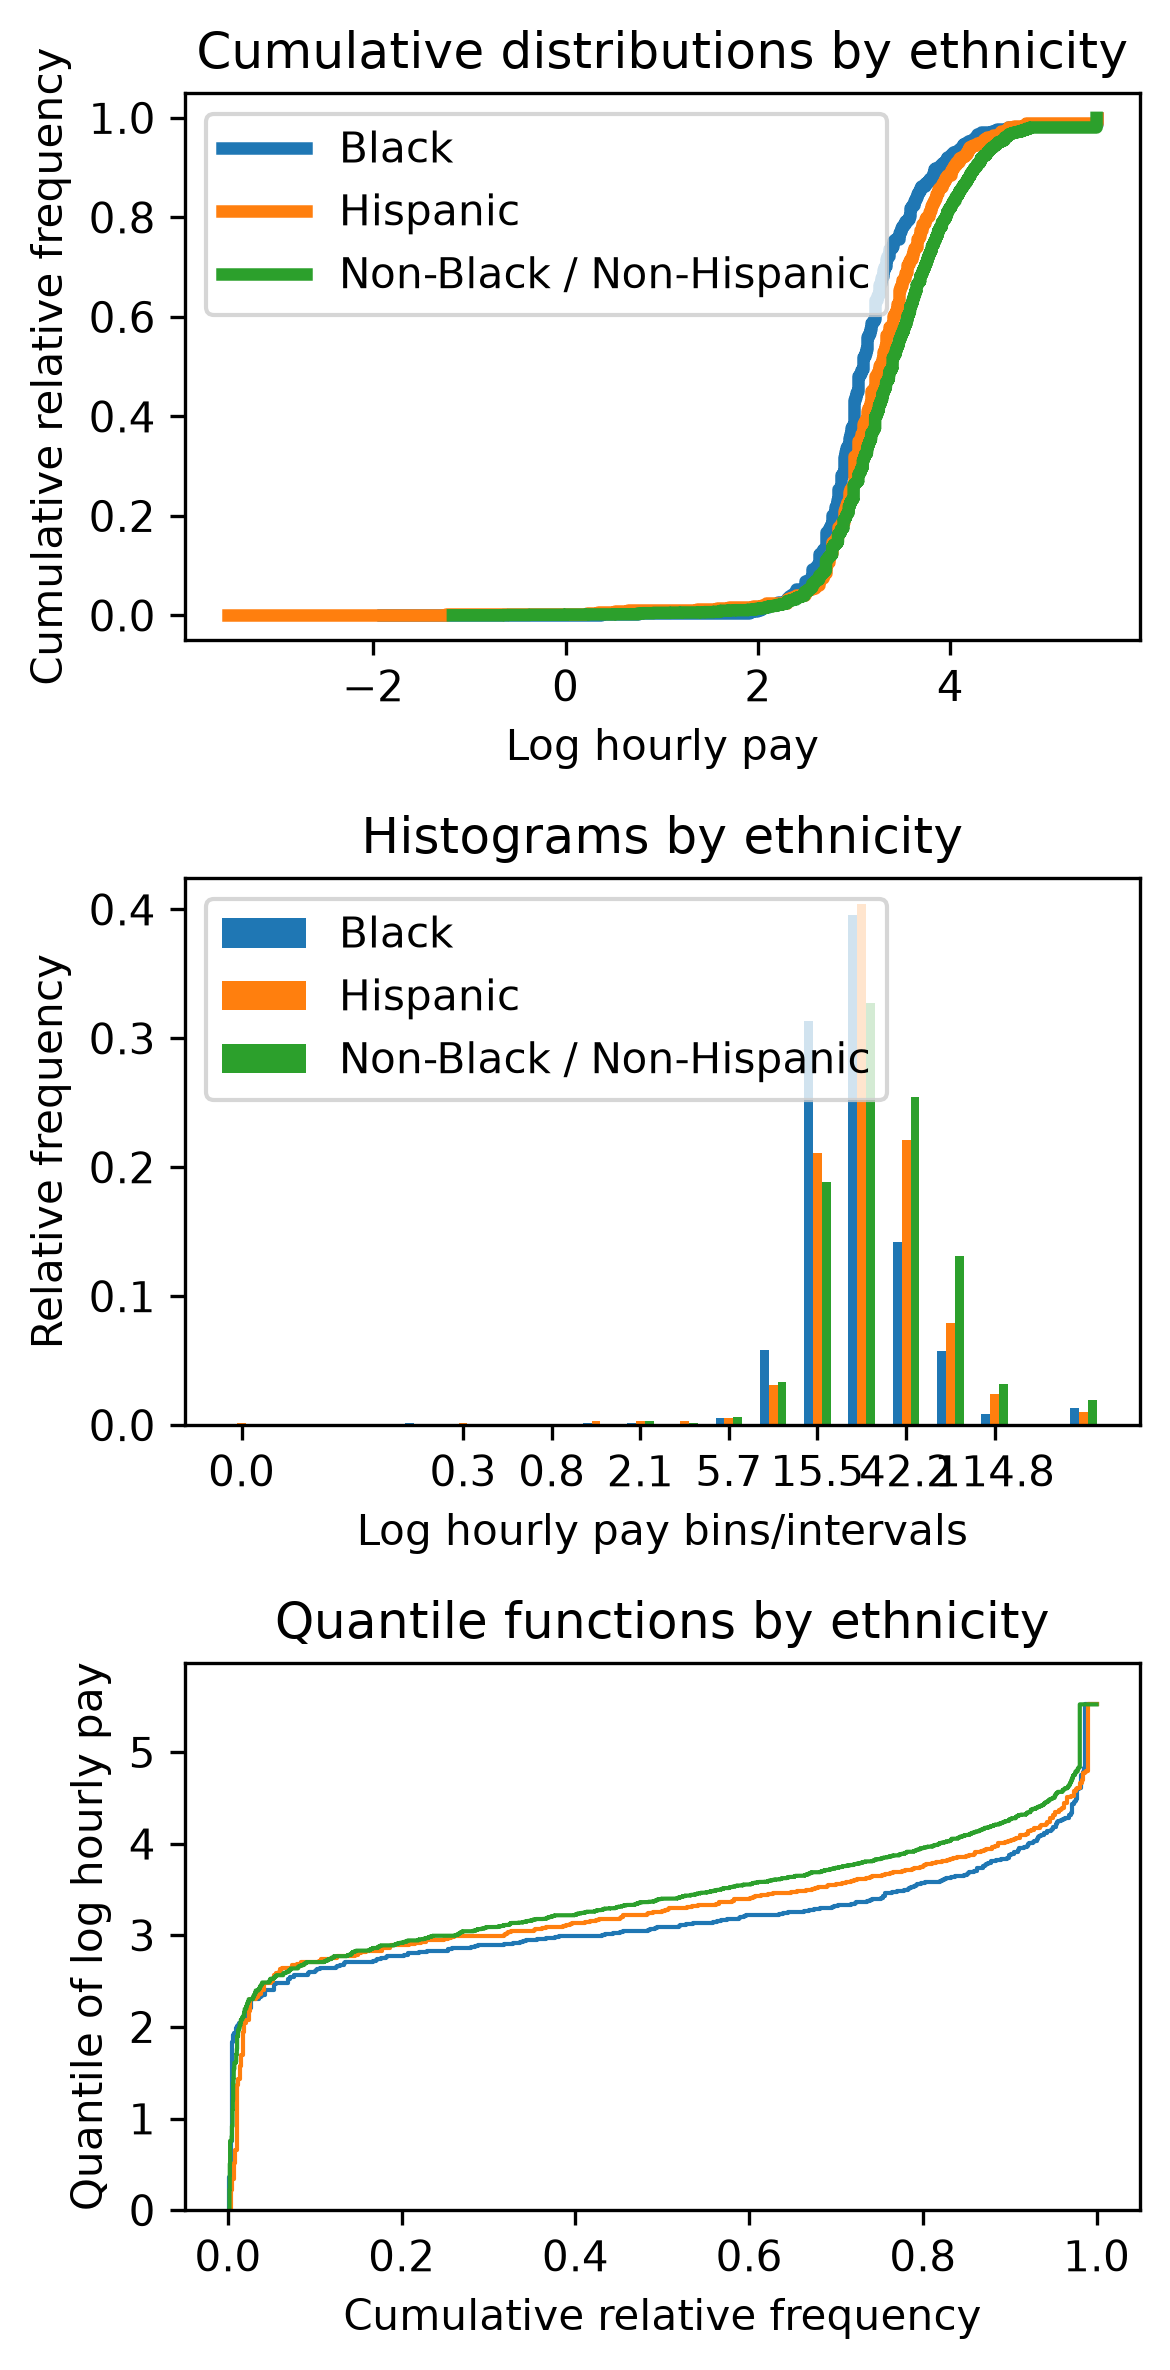

In [64]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(4,8), dpi=300)
# step plot
# let us specify it as:
# for each x value, 
# let the corresponding y value apply 
# until the next available x value in the dataframe 
# (on the right of/above the current x value)


for ethnicity in ['Black', 'Hispanic', 'Non-Black / Non-Hispanic']:
    # selecting the relevant dataframe (for the given ethnicity)
    df3_current = df3dict[ethnicity]
    # step plot
    axs[0].step(
        x=df3_current['log_hpay'], # variable of interest
        y=df3_current['cum_proportion'], # corresponding cumulative proportion
        where='post', # each time the y value applies above the x value (until the next x value)
        label=ethnicity,
        linewidth=3
    )
axs[0].legend()
axs[0].set_title('Cumulative distributions by ethnicity')
axs[0].set_ylabel('Cumulative relative frequency')
axs[0].set_xlabel('Log hourly pay')

for i in range(3):
    axs[1].bar(
        # have explicitly numerical type for the data plotted on the horizontal axis
        # choose the alignment according to the corresponding index
        x=ct['log_hpay_bin_mid'].astype(float) + bar_shift[i],
        height=ct[ethnicities[i]], # choose ethnicity according to the corresponding index
        width=0.2 * binwidth,
        label=ethnicities[i], # choose ethnicity according to the corresponding index
    )
axs[1].set_title('Histograms by ethnicity')
axs[1].set_ylabel('Relative frequency')
axs[1].set_xlabel('Log hourly pay bins/intervals')
ticks_locations = ct['log_hpay_bin_mid'].astype(float)[::2] # every second value
ticks_labels = np.round(np.exp(ticks_locations), decimals=1) # labels in hourly pay (not in logs)
axs[1].set_xticks(ticks=ticks_locations, labels=ticks_labels)
axs[1].legend()


# quantile functions / quantile plots
# inverse of the cumulative distributions
for ethnicity in ['Black', 'Hispanic', 'Non-Black / Non-Hispanic']:
    # selecting the relevant dataframe (for the given ethnicity)
    df3_current = df3dict[ethnicity]
    # step plot
    axs[2].step(
        # quantile is a value of the variable of interest
        y=df3_current['log_hpay'], # corresponding quantile
        # cumulative proportion for which the corresponding quantile is plotted
        x=df3_current['cum_proportion'], 
        where='pre', # each time the y value applies below the x value (until the previous x value)
        label=ethnicity,
        linewidth=1
    )
#axs[2].legend()
axs[2].set_title('Quantile functions by ethnicity')
axs[2].set_xlabel('Cumulative relative frequency')
axs[2].set_ylabel('Quantile of log hourly pay')
axs[2].set_ylim(bottom=0)


fig.tight_layout()